# OpenSurfaces: release inventory and annotation tables

This analysis uses the verified OpenSurfaces Release 0 archive and derived annotation tables. The objectives are to describe archive structure, identify the available vocabularies and document the scope of the tabular exports.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: repo


In [2]:
inventory = pd.read_csv(ROOT / "datasets/opensurfaces/archive_inventory.csv")
files = inventory[inventory["size_bytes"] > 0].copy()
print("Archive files:", len(files))
print("Total uncompressed bytes:", int(files.size_bytes.sum()))
print(files[["path", "size_bytes"]].to_string(index=False))

Archive files: 35
Total uncompressed bytes: 7472178587
                                                path  size_bytes
        opensurfaces/shapes.shapesubstancegroup.json        4812
           opensurfaces/mturk.experimentexample.json      416586
                   opensurfaces/mturk.mthittype.json     1140038
          opensurfaces/mturk.mtsubmittedcontent.json   803372596
   opensurfaces/mturk.mtqualificationassignment.json      107050
        opensurfaces/shapes.shapeplanaritylabel.json   223483165
          opensurfaces/mturk.mthitqualification.json      687044
              opensurfaces/shapes.materialshape.json   427039070
                  opensurfaces/licenses.license.json        3746
             opensurfaces/mturk.mtqualification.json        2085
                opensurfaces/mturk.mthitcontent.json   285788428
     opensurfaces/photos.photowhitebalancelabel.json    90261908
opensurfaces/shapes.shaperectifiednormalquality.json   149105395
                  opensurfaces/mtur

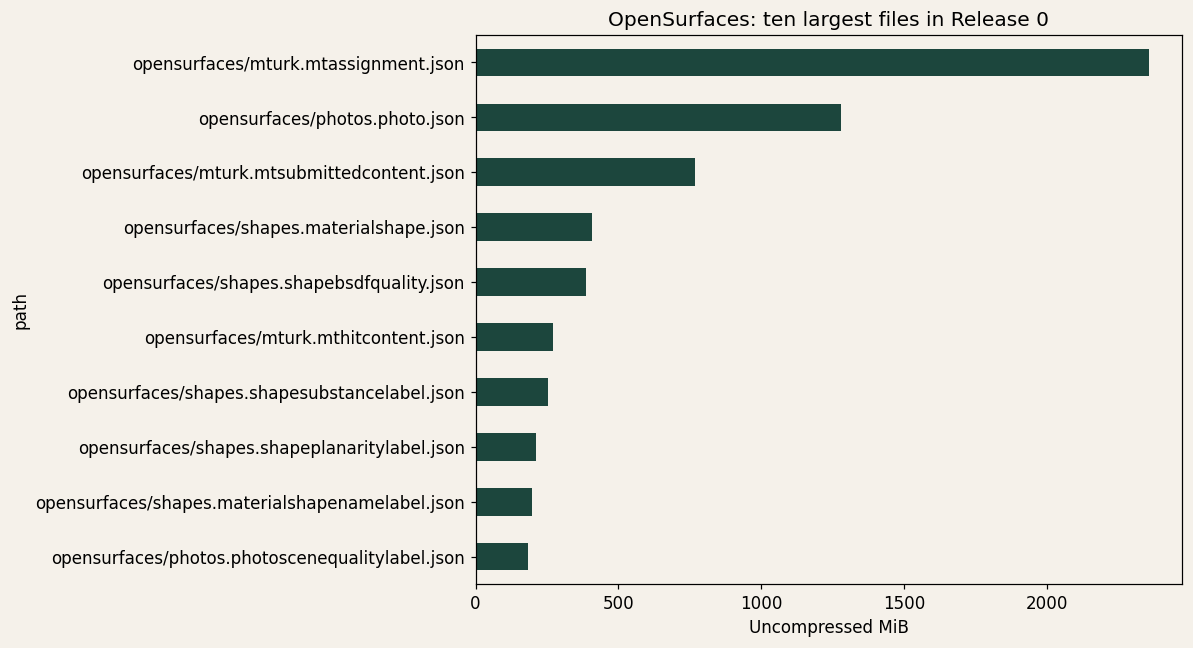

In [3]:
largest = files.nlargest(10, "size_bytes").set_index("path")["size_bytes"] / (1024 ** 2)
fig, ax = plt.subplots(figsize=(11, 6))
largest.sort_values().plot.barh(ax=ax, color="#1c463d")
ax.set_xlabel("Uncompressed MiB")
ax.set_title("OpenSurfaces: ten largest files in Release 0")
plt.tight_layout()
plt.show()

In [4]:
materials = pd.read_csv(ROOT / "datasets/opensurfaces/materials.csv")
print("Material vocabulary entries:", len(materials))
print(materials.to_string(index=False))
print("These are vocabulary entries, not counts of annotated surfaces.")

Material vocabulary entries: 48
 id  group                   name  parent  representative_shape  active  fail                                                                                                                                                    description
 30    NaN           I can't tell     NaN                   NaN   False  True                                                                                                                                                            NaN
 35    NaN More than one material     NaN                   NaN   False  True                                                                                                                                                            NaN
 31    NaN            Not on list     NaN                   NaN   False  True                                                                                                                                                            NaN
 16   10.0          

## Interpretation

The inventory measures file counts and storage requirements rather than material-surface frequency. Surface-frequency analysis requires processing the material-shape records and applying appropriate quality criteria. The original archive and processing helper are retained in GitHub Releases. Annotation rights are CC BY 4.0; photograph rights are recorded separately.

## CSV provenance

`materials.csv`, `material_groups.csv` and `photo_licenses.csv` were derived from `shapes.shapesubstance.json`, `shapes.shapesubstancegroup.json` and `licenses.license.json` in the original release. Record identifiers and source fields are retained.

The material vocabulary includes inactive and ambiguous entries. Selection of training categories requires review of the `active` and `fail` fields. Group `names` values represent source object-name identifiers, not material-surface counts. List-valued fields are stored as textual representations in the CSV exports.

Source: Sean Bell, Paul Upchurch, Noah Snavely and Kavita Bala, OpenSurfaces, SIGGRAPH 2013. Annotations: CC BY 4.0. Photograph rights remain independent.